# Relevant statistical concepts

We will focus on measures describing an association between a condition (e.g. illness) and e.g. an intervention or risk factor.

## Prevalence vs Incidence

**Prevalence**: Propoprtion of all people in study population with an outcome of interest (e.g. illness) at a particular time.
$$
Prevalence = \frac{People\hspace{2 mm}Affected}{People\hspace{2 mm}Study\hspace{2 mm}Population}
$$

Sometimes difference is made between **point prevalence** and **period prevalence**. There is no precise cutoff when to differentiate between a point and a period, as it normally takes time to enroll a sample population.

Another important term is **lifetime prevalence**, describing the proportion of individuals in a population that experience outcome of interest at any point in their life.

Prevalence has to be differentiated from **Incidence**, which is the proportion of *at-risk* subjects developing the outcome of interest.
$$
Incidence = \frac{New\hspace{2 mm}Cases}{At\hspace{2 mm}Risk\hspace{2 mm}People\hspace{2 mm}in\hspace{2 mm}Study\hspace{2 mm}Population}
$$

**Incidence rate** describes the frequency at which an event occurs over a specified period of time.

# Risk vs Odds

**Risk**: Probability that an outcome will occur.

**Odds**: Probability that an event will occur *divided* by the probability that event does not occur.

Applied to e.g. a disease in a population.
$$
Risk = \frac{N\hspace{2 mm}Disease}{N\hspace{2 mm}Disease + No\hspace{2 mm}Disease}
$$
$$
Odds = \frac{N\hspace{2 mm}Disease}{N\hspace{2 mm}No\hspace{2 mm}Disease}
$$

**The magnitude that risk and odds differ  varies based in event rate**. If frequency in population is high, then odds would “overestimate“ danger. If frequency of event is rare, then outcomes between risk and odds will align more.

Let's visualize this with a study population of N = 5000 and increasing the frequency of individuals with a disease.


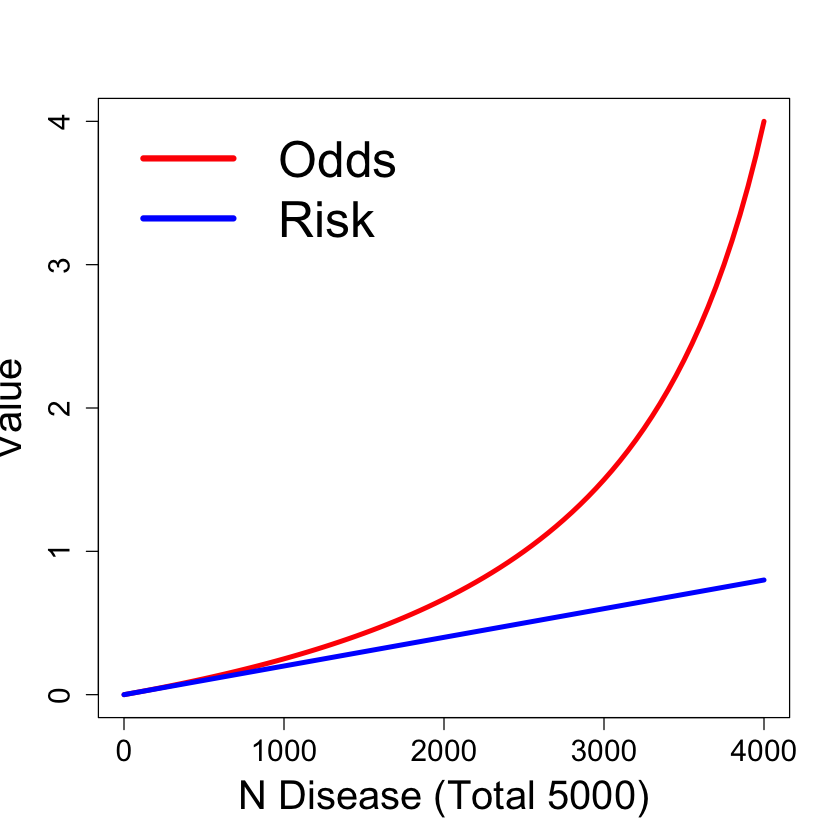

In [1]:
# Define a function to calculate risk
calculate_risk <- function(n_disease, n_no_disease) {
    return(n_disease / (n_disease + n_no_disease))
}

# Define a function to calculate odds
calculate_odds <- function(n_disease, n_no_disease) {
    return(n_disease / n_no_disease)
}

ntotal <- 5000
n_disease <- seq(0,4000,50)
n_no_disease <- (rep(ntotal, length(n_disease)) - n_disease)

risk_vec <- calculate_risk(n_disease, n_no_disease)
odds_vec <- calculate_odds(n_disease, n_no_disease)

par(bg = "white")
plot(n_disease, odds_vec, type= 'l', col = 'red', lwd = 4, 
        cex.lab = 2, cex.axis = 1.5, ylab=c('Value'), xlab = c("N Disease (Total 5000)"))
lines(n_disease, risk_vec, col = 'blue', lwd = 4)
legend("topleft",c('Odds', 'Risk'), cex = 2.5, col = c('red', 'blue'), lwd=5, bty = "n")


**The figure shows that Odds and Risk should NOT be confused.**

# Relative Risk vs Odds Ratios

These measures help us putting the risk and odds values into a better context, e.g. of intervention and no intervention. **Relative Risk** and **Odds Ratio** are popular measure that allow meaningful assessment of relationship between an intervention / exposure and an outcome, by comparing risk / odds between groups.

 Relative risk (RR) and odds ratios (OR) are simply the risk or odds, respectively, of an outcome in one group divided by the risk or odds of the outcome in another other group. The interpretation of both measures are similar:
 - OR | RR = 1; no enhanced risk / odds between groups
 - OR | RR > 1;  enhanced risk / odds for exposed / intervention group
 - OR | RR < 1;  decreased risk / odds for exposed / intervention group
 
 Here 2 R functions, where “exposed“ or “unexposed“ refers to e.g. an intervention or some other potentially factor health factor (e.g smoking) and cases to an outcome (e.g. lung cancer).

In [2]:
# Function to calculate relative risk
calculate_relative_risk <- function(exposed_cases, exposed_noncases, unexposed_cases, unexposed_noncases) {
    exposed_risk <- exposed_cases / (exposed_cases + exposed_noncases)
    unexposed_risk <- unexposed_cases / (unexposed_cases + unexposed_noncases)
    return(exposed_risk / unexposed_risk)
}

# Function to calculate odds ratio
calculate_odds_ratio <- function(exposed_cases, exposed_noncases, unexposed_cases, unexposed_noncases) {
    exposed_odds <- exposed_cases / exposed_noncases
    unexposed_odds <- unexposed_cases / unexposed_noncases
    return(exposed_odds / unexposed_odds)
}

#taking some sample data on smoking:
#https://www.researchgate.net/publication/13528112_Occupational_risk_factors_for_lung_cancer_a_case-control_study_in_West_Germany

nonsmokers_nocancer <- 138 + 98 #adding males & females
nonsmokers_cancer <- 18 + 53
heavysmokers_nocancer <- 114 + 4 #only >40
heavysmokers_cancer <- 266 + 50

RR_smoking <- calculate_relative_risk(heavysmokers_cancer, heavysmokers_nocancer, nonsmokers_cancer, nonsmokers_nocancer)
OR_smoking <- calculate_odds_ratio(heavysmokers_cancer, heavysmokers_nocancer, nonsmokers_cancer, nonsmokers_nocancer)

print(paste('The relative risk of is ', RR_smoking))
print(paste('The odds ratio of is ', OR_smoking))

[1] "The relative risk of is  3.14830921009931"
[1] "The odds ratio of is  8.90140845070423"


Both measures can be used for similar questions. However when studies compare the incidence of an event e.g. in a clinical trial, RR is often prefered, as OR normally “overstates“ the magnitude of an effect. As above this divergence increases with the frequency of the event.

Let's take the data from above and mess aroud with the numbers to plot the RR vs OR. We will keep the numbers the same for non-smokers, but vary the numbers for the smokers keepng the N constant.

In [3]:
NSmokers <- heavysmokers_nocancer + heavysmokers_cancer
NSmokers


[1] 434

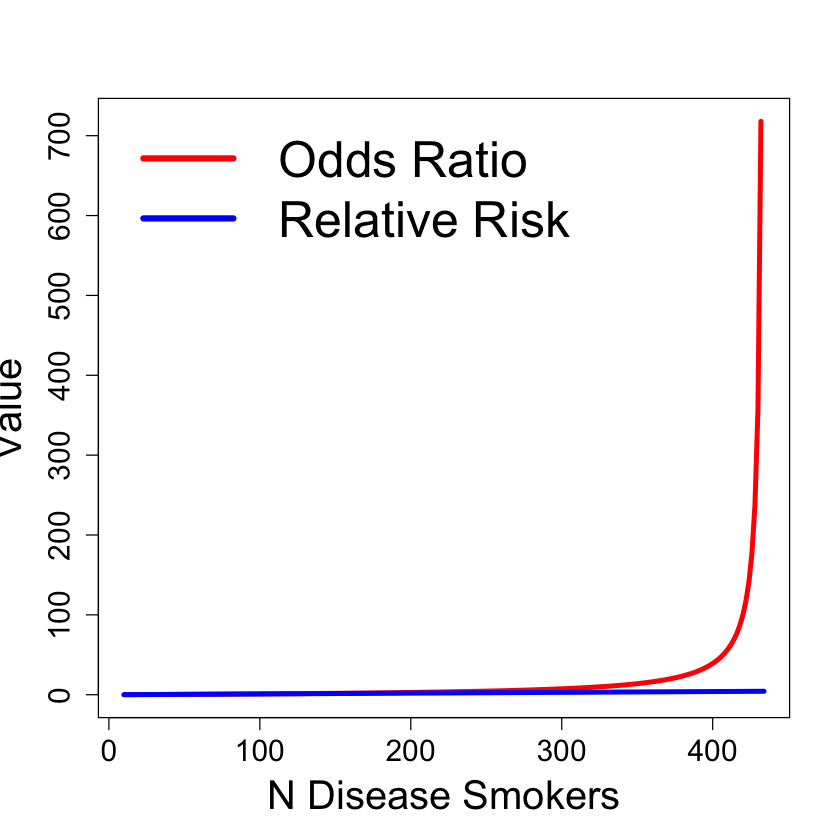

In [4]:
#NSmokers <- heavysmokers_nocancer + heavysmokers_cancer
heavysmokers_cancer <- seq(10,NSmokers,2) 
heavysmokers_nocancer <- rep(NSmokers, length(heavysmokers_cancer)) - heavysmokers_cancer

nonsmokers_nocancer <- rep(nonsmokers_nocancer, length(heavysmokers_cancer))
nonsmokers_cancer <- rep(nonsmokers_cancer, length(heavysmokers_cancer))

RR_smoking_vec <- calculate_relative_risk(heavysmokers_cancer, heavysmokers_nocancer, nonsmokers_cancer, nonsmokers_nocancer)
OR_smoking_vec <- calculate_odds_ratio(heavysmokers_cancer, heavysmokers_nocancer, nonsmokers_cancer, nonsmokers_nocancer)

par(bg = "white")
plot(heavysmokers_cancer, OR_smoking_vec, type= 'l', col = 'red', lwd = 4, 
        cex.lab = 2, cex.axis = 1.5, ylab=c('Value'), xlab = c("N Disease Smokers"))
lines(heavysmokers_cancer, RR_smoking_vec, col = 'blue', lwd = 4)
legend("topleft",c('Odds Ratio', 'Relative Risk'), cex = 2.5, col = c('red', 'blue'), lwd=5, bty = "n")

In case you have an OR and want to estimate the RR, you can use the following formula, where p0 is the baseline risk in the unexposed group.

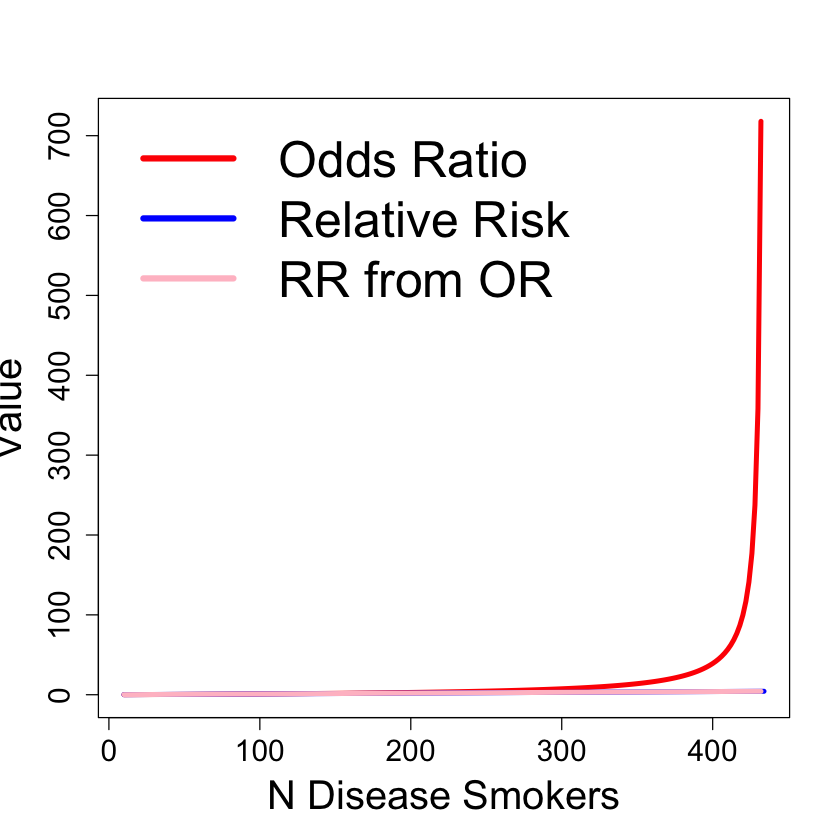

In [5]:
OR_to_RR <- function(OR, p0) {
  # OR = odds ratio
  # p0 = baseline risk (risk in control group, e.g., 0.1 for 10%)
  RR <- OR / ((1 - p0) + (p0 * OR))
  return(RR)
}
baseline_risk <- nonsmokers_cancer / (nonsmokers_cancer + nonsmokers_nocancer)
RR_from_OR_vec <- OR_to_RR(OR_smoking_vec, baseline_risk)

par(bg = "white")
plot(heavysmokers_cancer, OR_smoking_vec, type= 'l', col = 'red', lwd = 4, 
        cex.lab = 2, cex.axis = 1.5, ylab=c('Value'), xlab = c("N Disease Smokers"))
lines(heavysmokers_cancer, RR_smoking_vec, col = 'blue', lwd = 4)
lines(heavysmokers_cancer, RR_from_OR_vec, col = 'pink', lwd = 4)
legend("topleft",c('Odds Ratio', 'Relative Risk', 'RR from OR'), cex = 2.5, col = c('red', 'blue', 'pink'), lwd=5, bty = "n")

For so-called **case control studies** ORs are the method of choice. In these *retrospective* observational studies, the cases (e.g. with a disease) and controls (e.g. no disease) are identified first, i.e. starts with the outcome of interest, and the frequency of an exposure is compared to estimate the potential contribution of this factor (“odds of an exposure“).

Sometimes you will also encounter Hazard Ratios (HR). These are used in **survival analysis**, where the time until an event occurs is of interest. The HR describes the ratio of the hazard rates between two groups over time.

# Logistic Regression

Can be used when we have also continuous variables (e.g. number of cigarettes per day; no need to “artiicially“ categorize with some break points) and - importantly more than one explanatory variable. This allows to quantify the impact of each variable on the OR and is a powerful feature when controlling for confounding effects.

In general Logistic regression is similar to linear regression with the difference that the response variable is *binomial*.

$$
log(\frac{\pi}{1-\pi}) = \beta _{0} + \beta _{0} x_{0} + \beta _{1} x_{1} + \beta _{2} x_{2} ... + \beta _{n} x_{n}
$$

$\pi$ is the probability of an event (e.g., death) and $\beta_{i}$ are the regression coefficients. Importantly $\beta _{0}$ constitute the *reference level* for all variables. A reference level could e.g. be in a study investigating the influence of sex and smoking on death, non-smoking males.
In order to get the Odds of e.g. the reference level we need to take the exponent of the coefficient, i.e. $exp(\beta_{0})$. In our example above the first variable could be sex, so $exp(\beta_{1})$ would be the odds for females. Correspondingly, $exp(\beta_{2})$ would be the odds for smokers. For female smokers, the odds would be $exp(\beta_{1} + \beta_{2})$. 

**Rememeber: The odds will always be with respect to the *reference level*.** So if the probability of an event in your reference level is small, then it may still be small in a group of interest, even it the odds are high.


Here is an example using data by [Reisinger et al.](https://bmcmedicine.biomedcentral.com/articles/10.1186/s12916-023-02998-1), which aimed at understanding better the relationship between aging and hearing loss on the probability of experiencing chronic tinnitus. We will only focus on the data by [NHANES](https://www.cdc.gov/nchs/nhanes/index.htm).

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”


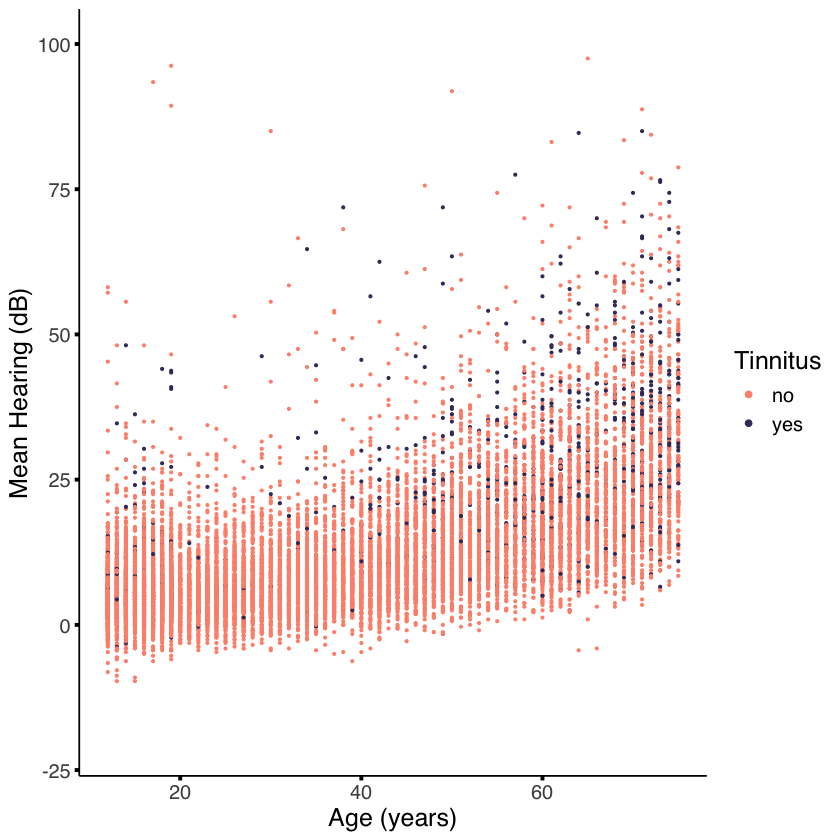

In [6]:
library(ggplot2)

load("explainOR/data/NHANES_Tinn.Rda")

#some preprocessing, excluding e.g. who only occasionally report tinnitus
AllData_Sub <- AllData[which(AllData$Tinnitus == 1 | AllData$Tinnitus == 2),]
AllData_Sub <- AllData_Sub[-which(AllData_Sub$TinnFreq == 9),]
AllData_Sub$TinnFreq <- abs(AllData_Sub$TinnFreq - 6)
AllData_Sub$TinnFreq[which(is.na(AllData_Sub$TinnFreq))] <- 0
AllData_Sub <- AllData_Sub[-which(AllData_Sub$Age > 75),]
AllData_Sub_PureCases <- AllData_Sub[which(AllData_Sub$TinnFreq == 0 | AllData_Sub$TinnFreq == 5),]
AllData_Sub_PureCases$Tinnitus <- abs(AllData_Sub_PureCases$Tinnitus - 2)
AllData_Sub_PureCases$HL_mean <- rowMeans(AllData_Sub_PureCases[,c(21,22)], na.rm = TRUE)

#plot the relationship

ggplot(AllData_Sub_PureCases, aes(x = Age, y = HL_mean, color = factor(Tinnitus))) +
  geom_point(size=.5)+
  ylim(-20,100)+  
  scale_color_manual(labels=c('no', 'yes'), values=c('#FF927A','#3F3869'))+
  theme_classic()+
  theme(text=element_text(family='Helvetica',size = 15),
        element_line(colour = 'black', size = 1.1),
        axis.ticks = element_line(colour = 'black', linewidth = 1.1))+
  ylab('Mean Hearing (dB)')+
  xlab('Age (years)')+
  labs(colour='Tinnitus')+
  guides(color=guide_legend(override.aes=list(fill=NA)))+
  guides(color = guide_legend(override.aes = list(size = 1.5)))
  

We will define 2 age categories and use hearing threshold as continuous variable.

In [7]:
AllData_Sub_PureCases$AgeCat <- rep(NA, length(AllData_Sub_PureCases$Age))
AllData_Sub_PureCases$AgeCat[AllData_Sub_PureCases$Age >= median(AllData_Sub_PureCases$Age)] <- 'older'
AllData_Sub_PureCases$AgeCat[AllData_Sub_PureCases$Age < median(AllData_Sub_PureCases$Age)] <- 'younger'
AllData_Sub_PureCases$AgeCat<-as.factor(AllData_Sub_PureCases$AgeCat)

Now we can calculate the logistic regression predicting the binomial outcome “Tinnitus“.

In [8]:
model1 <- glm( Tinnitus ~ AgeCat+HL_mean, data = AllData_Sub_PureCases, 
                     family = binomial)
summary(model1)


Call:
glm(formula = Tinnitus ~ AgeCat + HL_mean, family = binomial, 
    data = AllData_Sub_PureCases)

Coefficients:
               Estimate Std. Error z value Pr(>|z|)    
(Intercept)   -3.597416   0.074665 -48.181   <2e-16 ***
AgeCatyounger  0.058283   0.080450   0.724    0.469    
HL_mean        0.056822   0.002469  23.015   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 7574.2  on 16007  degrees of freedom
Residual deviance: 6940.8  on 16005  degrees of freedom
AIC: 6946.8

Number of Fisher Scoring iterations: 6


As you can see the reference level are “old“ individuals with 0dB hearing loss. For these indivuals the odds are $exp(-3.597416) = .027$, i.e. ~3%. In this model, age is not significant. So we could simplify the model.

In [9]:
model2 <- glm( Tinnitus ~ HL_mean, data = AllData_Sub_PureCases, 
                     family = binomial)
summary(model2)


Call:
glm(formula = Tinnitus ~ HL_mean, family = binomial, data = AllData_Sub_PureCases)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) -3.559676   0.053025  -67.13   <2e-16 ***
HL_mean      0.055940   0.002142   26.11   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 7574.2  on 16007  degrees of freedom
Residual deviance: 6941.3  on 16006  degrees of freedom
AIC: 6945.3

Number of Fisher Scoring iterations: 5


The odds of an individual with 0 dB hearing threshold is ~3%. For each dB increase, the odds increase by $exp(0.055940) = 1.055$, i.e. ~6%.


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


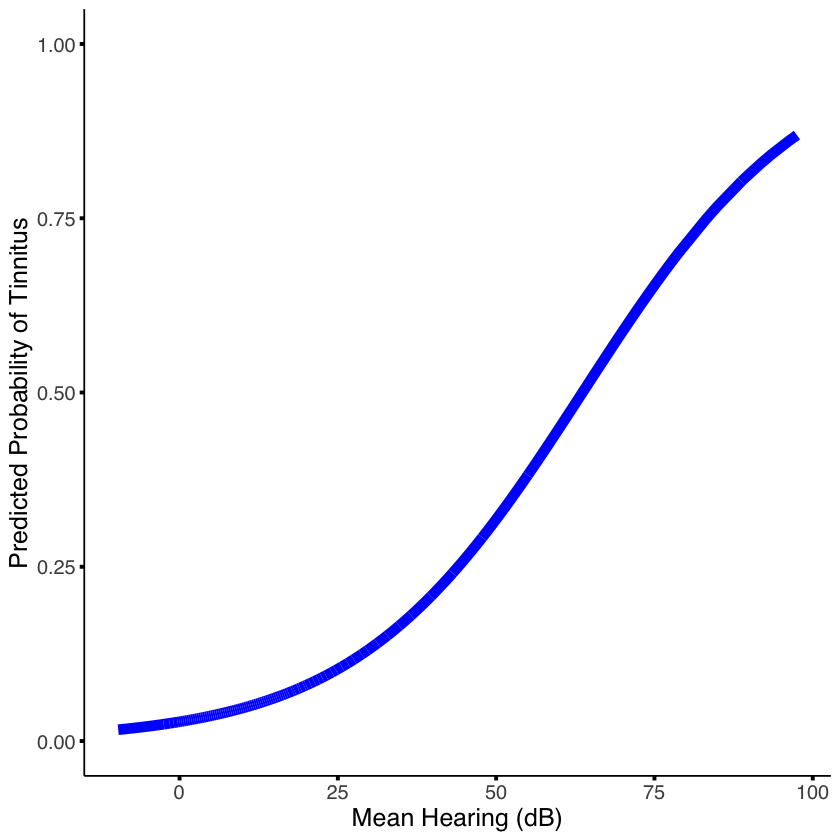

In [10]:
# predict probabilities for each observation
AllData_Sub_PureCases$prob <- predict(model2, type = "response")

# create scatterplot
ggplot(AllData_Sub_PureCases, aes(x = HL_mean, y = prob)) +
  #geom_point(size=4, col = 'red')+
  geom_line(aes(x = HL_mean, y = prob), color = 'blue', size = 3) +  ylim(0,1)+  
  scale_color_manual(labels=c('no', 'yes'), values=c('#FF927A','#3F3869'))+
  theme_classic()+
  theme(text=element_text(family='Helvetica',size = 15),
      element_line(colour = 'black', size = 1.1),
      axis.ticks = element_line(colour = 'black', size = 1.1))+
  ylab('Predicted Probability of Tinnitus')+
  xlab('Mean Hearing (dB)')+
  labs(colour='Tinnitus')+
  guides(color=guide_legend(override.aes=list(fill=NA)))+
  guides(color = guide_legend(override.aes = list(size = 1.5)))

## Literature


Monaghan, T. F. et al. Foundational Statistical Principles in Medical Research: A Tutorial on Odds Ratios, Relative Risk, Absolute Risk, and Number Needed to Treat. Int. J. Environ. Res. Public Heal. 18, 5669 (2021).

Ranganathan, P., Aggarwal, R. & Pramesh, C. S. Common pitfalls in statistical analysis: Odds versus risk. Perspect. Clin. Res. 6, 222–224 (2015).
  